In [ ]:
# ================= Data Analysis & Calculation =================
import pandas as pd
import numpy as np

# ================= Data Visualization =================
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

# ================= Model Building & Data Partition =================
import statsmodels.api as sm
from statsmodels.stats import diagnostic as diag
from sklearn.model_selection import train_test_split

In [ ]:
new =pd.read_csv(r"Salary_Data.csv")
new.head()

,YearsExperience,Salary
0,1.1,39.343
1,1.3,46.205
2,1.5,37.731
3,2.0,43.525
4,2.2,39.891


In [ ]:
new.tail()


,YearsExperience,Salary
25,9.0,105.582
26,9.5,116.969
27,9.6,112.635
28,10.3,122.391
29,10.5,121.872


In [ ]:
new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [ ]:
new.describe()

,YearsExperience,Salary
count,30.000000,30.00000
mean,5.313333,76.00300
std,2.837888,27.41443
min,1.100000,37.73100
25%,3.200000,56.72075
50%,4.700000,65.23700
75%,7.700000,100.54475
max,10.500000,122.39100


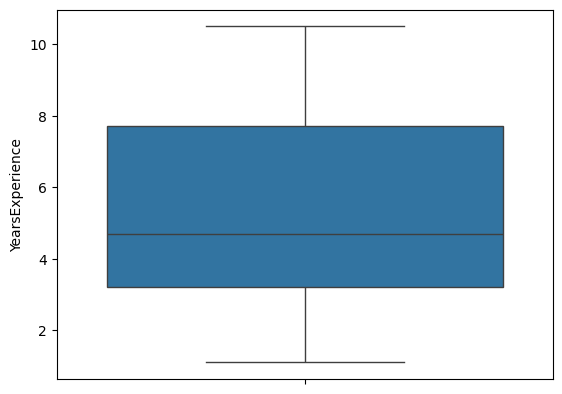

In [ ]:
sns.boxplot(y='YearsExperience',data=new)
plt.show()

In [ ]:
new.isna().sum()

,0
YearsExperience,0
Salary,0


In [ ]:
new.head()


,YearsExperience,Salary
0,1.1,39.343
1,1.3,46.205
2,1.5,37.731
3,2.0,43.525
4,2.2,39.891


In [ ]:
from sklearn.model_selection import train_test_split

x = new[['YearsExperience']]
y = new[['Salary']]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, train_size=0.7, random_state=100
)

In [ ]:
train = pd.concat([x_train,y_train], axis=1)
plt.show()

In [ ]:
train = pd.concat([x_train,y_train] , axis=1)
plt.show()

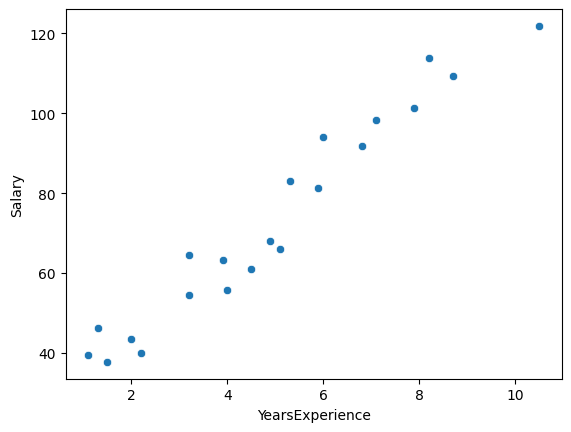

In [ ]:
sns.scatterplot(x='YearsExperience',y='Salary',data=train)
plt.show()

In [ ]:
train.corr()

,YearsExperience,Salary
YearsExperience,1.000000,0.974123
Salary,0.974123,1.000000


<function matplotlib.pyplot.show(close=None, block=None)>

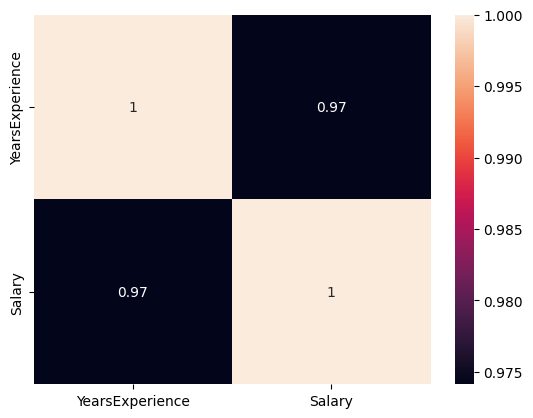

In [ ]:
sns.heatmap(train.corr(),annot=True)
plt.show

In [ ]:
import statsmodels.formula.api as smf
model = smf.ols('Salary ~ YearsExperience', data=train).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.949
Model:                            OLS   Adj. R-squared:                  0.946
Method:                 Least Squares   F-statistic:                     352.9
Date:                Wed, 06 May 2026   Prob (F-statistic):           9.91e-14
Time:                        08:09:31   Log-Likelihood:                -66.742
No. Observations:                  21   AIC:                             137.5
Df Residuals:                      19   BIC:                             139.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          25.2029      2.875      8.765      0.000      19.185      31.221
YearsExperience     9.7312      0.518     18.786      0.000       8.647      10.815
==============================================================================
Omnibus:                        1.843   Durbin-Watson:                   1.749
Prob(Omnibus):                  0.398   Jarque-Bera (JB):                1.106
Skew:                           0.219   Prob(JB):                        0.575
Kurtosis:                       1.964   Cond. No.                         12.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
train['fitted_value'] = model.fittedvalues
train['residual'] = model.resid
train.head()

,YearsExperience,Salary,fitted_value,residual
17,5.3,83.088,76.778268,6.309732
22,7.9,101.302,102.079398,-0.777398
11,4.0,55.794,64.127703,-8.333703
4,2.2,39.891,46.611536,-6.720536
29,10.5,121.872,127.380528,-5.508528
